## **Part A | Data Quality & Basic Insights**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Load and inspect the dataset

In [2]:
data=pd.read_csv('sales_raw.csv')
print("Data is",data.head())
print("Shape of data is",data.shape)
print("The columns in dataset are",data.columns)
print("The data types of columns in dataset are",data.dtypes)

print()

null_values=data.isna().sum()
print("The total null values per column are\n", null_values, "\n")

duplicate_rows=data.duplicated().sum()
print("The total duplicate rows are\n", duplicate_rows, "\n")


Data is    transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250
Shape of data is (21, 6)
The columns in dataset are Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price'],
      dtype='object')
The data types of columns in dataset are transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object

The total null values per column are
 transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64 

The total duplicate rows 

## **2. Clean the dataset**



## Trim extra spaces and standardize inconsistent text in region and category.

In [3]:
data["region"]= data["region"].str.strip().str.title()
data["category"]= data["category"].str.strip().str.title()


## Handle missing values, invalid prices and duplicates using sensible rules; explain the choices.

In [4]:
print("The data types of columns are", data.dtypes)
data["sale_date"] = pd.to_datetime(data["sale_date"], errors="coerce")
# First, I will find out the outliers so to better decde how to fill na values in different columns
numeric_col=['quantity', 'unit_price']
for col in numeric_col:
    data[col]=pd.to_numeric(data[col], errors="coerce")
    q1=data[col].quantile(0.25)
    q3=data[col].quantile(0.75)

    IQR=q3-q1

    lower_bound=q1-1.5*IQR
    upper_bound=q3+1.5*IQR

    outliers=data[ (data[col]<lower_bound) | (data[col]>upper_bound)]
    data.loc[data[col]<0, col]=0
    print()
    print("The outliers are\n", outliers, "\n")

# for data time columns
print(data[data["sale_date"].isna()])
# becuase I had one queantty as -2, I will equalize it to 0
data.loc[data["quantity"] < 0, "quantity"] = 0

# 1. Calculate the mode first
mode_date = data['sale_date'].mode()[0]

# 2. Fill the missing values with that mode
print("Mode date:", mode_date)

data['sale_date'] = data['sale_date'].fillna(mode_date)

print(data[data["transaction_id"] == 1014])

The data types of columns are transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object

The outliers are
     transaction_id  sale_date region category  quantity unit_price
8             1009 2026-10-05   West     Food       5.0         90
12            1013 2026-10-07  South     Food      -2.0        130 


The outliers are
     transaction_id  sale_date region    category  quantity  unit_price
15            1016 2026-10-08  North  Stationery       1.0     10000.0 

    transaction_id sale_date region category  quantity  unit_price
13            1014       NaT   West    Books       2.0       300.0
Mode date: 2026-10-02 00:00:00
    transaction_id  sale_date region category  quantity  unit_price
13            1014 2026-10-02   West    Books       2.0       300.0


### Printing all the data to now check any missing value or outliers

In [5]:
print(data)

    transaction_id  sale_date region    category  quantity  unit_price
0             1001 2026-10-01  North        Food       2.0       120.0
1             1002 2026-10-01  South       Books       1.0       250.0
2             1003 2026-10-02  North        Food       3.0       110.0
3             1004 2026-10-02   East  Stationery       4.0        50.0
4             1005 2026-10-03  South       Books       2.0       250.0
5             1006 2026-10-03   West        Food       NaN       130.0
6             1007 2026-10-04  North  Stationery       3.0        60.0
7             1008 2026-10-04   East       Books       1.0       300.0
8             1009 2026-10-05   West        Food       5.0        90.0
9             1010 2026-10-05  South  Stationery       2.0         NaN
10            1011 2026-10-06   East        Food       2.0         NaN
11            1012 2026-10-06  North       Books       1.0       320.0
12            1013 2026-10-07  South        Food       0.0       130.0
13    

In [6]:
# for numeric data types fill NaN values with mean or median.
quantity_mean = data['quantity'].mean()
data['quantity']= data['quantity'].fillna(quantity_mean)

# for string data types like region and category, fill values with mode
data['region']= data['region'].fillna(data['region'].mode()[0])
data['category']= data['category'].fillna(data['category'].mode()[0])

print(data.isna().sum())


transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        2
dtype: int64


In [7]:
# in case of unit price for stationary catgeory, 10000 is an outlier, so I am swapping it with the median
stationary_median= data["unit_price"].loc[data['category']=="Stationery"].median()
print("The median of stationary category is", stationary_median)

# I will replace the outlier value of 10000 with the median value of stationary category
mask = (data["category"] == "Stationery") & (data["unit_price"] == 10000)
data.loc[mask, "unit_price"]=stationary_median


The median of stationary category is 55.0


In [8]:
# Now it is time to handle the missing values for numeric columns unit_price and revenue.
# First finding the mean and median of the unt_price and revenue columns to decide whether to fill with men or median
print("Mean of unit price is", data["unit_price"].mean()) # 127
print("Median of unit price is",data["unit_price"].median()) # 110, this is more preferred

# fill NaN values in unit_price with the median because it is less sensitive to outliers
data["unit_price"]=data["unit_price"].fillna(data["unit_price"].median())


Mean of unit price is 148.94736842105263
Median of unit price is 120.0


In [9]:
print(data)

    transaction_id  sale_date region    category  quantity  unit_price
0             1001 2026-10-01  North        Food      2.00       120.0
1             1002 2026-10-01  South       Books      1.00       250.0
2             1003 2026-10-02  North        Food      3.00       110.0
3             1004 2026-10-02   East  Stationery      4.00        50.0
4             1005 2026-10-03  South       Books      2.00       250.0
5             1006 2026-10-03   West        Food      2.25       130.0
6             1007 2026-10-04  North  Stationery      3.00        60.0
7             1008 2026-10-04   East       Books      1.00       300.0
8             1009 2026-10-05   West        Food      5.00        90.0
9             1010 2026-10-05  South  Stationery      2.00       120.0
10            1011 2026-10-06   East        Food      2.00       120.0
11            1012 2026-10-06  North       Books      1.00       320.0
12            1013 2026-10-07  South        Food      0.00       130.0
13    

## Compare the row count before and after cleaning; preserve the original input CSV

In [10]:
print("Duplicated rows are", data.duplicated().sum(), "\n")
print(data[data.duplicated(keep=False)])
print("Total number of rows in dataset are", len(data), "\n")

# dropping the duplicate rows
data.drop_duplicates(inplace=True)
print("Total number of rows in dataset after removing duplicates are", len(data), "\n")

# Now there are no duplicate rows in the dataset


Duplicated rows are 1 

    transaction_id  sale_date region category  quantity  unit_price
2             1003 2026-10-02  North     Food       3.0       110.0
20            1003 2026-10-02  North     Food       3.0       110.0
Total number of rows in dataset are 21 

Total number of rows in dataset after removing duplicates are 20 



## **3. Calculate and analyze**

```Add a revenue column: quantity × unit_price.```

```Use groupby() to summarize revenue by region or category.```

```Create two labelled charts and write two evidence-based findings.```



In [11]:
data["revenue"]=data["unit_price"]*data["quantity"]
print(data.head(5))

   transaction_id  sale_date region    category  quantity  unit_price  revenue
0            1001 2026-10-01  North        Food       2.0       120.0    240.0
1            1002 2026-10-01  South       Books       1.0       250.0    250.0
2            1003 2026-10-02  North        Food       3.0       110.0    330.0
3            1004 2026-10-02   East  Stationery       4.0        50.0    200.0
4            1005 2026-10-03  South       Books       2.0       250.0    500.0


In [12]:
# groupby to summarize revenue by region and category
summary=data.groupby(["region", "category"])["revenue"].sum()
print(summary)

region  category  
East    Books         300.0
        Food          480.0
        Stationery    200.0
North   Books         720.0
        Food          970.0
        Stationery    235.0
South   Books         750.0
        Food          285.0
        Stationery    240.0
West    Books         600.0
        Food          742.5
        Stationery     80.0
Name: revenue, dtype: float64


In [13]:
# now dataset has a revenue column as well
print(data.head)

<bound method NDFrame.head of     transaction_id  sale_date region    category  quantity  unit_price  \
0             1001 2026-10-01  North        Food      2.00       120.0   
1             1002 2026-10-01  South       Books      1.00       250.0   
2             1003 2026-10-02  North        Food      3.00       110.0   
3             1004 2026-10-02   East  Stationery      4.00        50.0   
4             1005 2026-10-03  South       Books      2.00       250.0   
5             1006 2026-10-03   West        Food      2.25       130.0   
6             1007 2026-10-04  North  Stationery      3.00        60.0   
7             1008 2026-10-04   East       Books      1.00       300.0   
8             1009 2026-10-05   West        Food      5.00        90.0   
9             1010 2026-10-05  South  Stationery      2.00       120.0   
10            1011 2026-10-06   East        Food      2.00       120.0   
11            1012 2026-10-06  North       Books      1.00       320.0   
12      

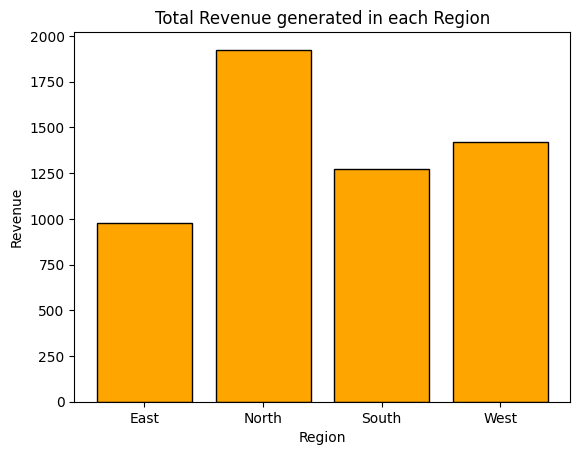

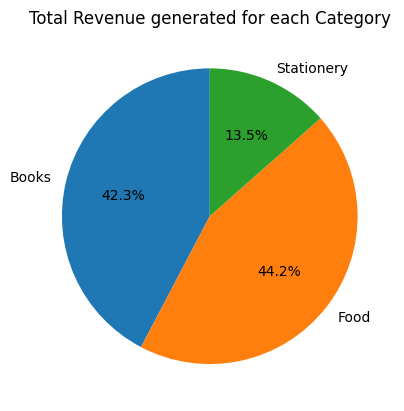

In [14]:
#  Create two labelled charts and write two evidence-based findings

# First chart
x=data.groupby("region")["revenue"].sum()
plt.bar(x.index, x.values, color='orange', edgecolor='black')
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.title("Total Revenue generated in each Region")
plt.show()

# second chart
print()
# Pie chart – Sales distribution by category
x=data.groupby('category')['revenue'].sum()
plt.pie(x, labels=x.index, autopct="%1.1f%%", startangle=90)
plt.title("Total Revenue generated for each Category")
plt.show()


# **Evidence Based Findings**

##```1. In the revenue generated per region, the total revenue is generated in the North region with the tren following as ***North > West > South > East***```
##```2. In the rvenue generated per category, the highest revenue is generated by Books with the trend following as ***Food > Books > Stationery***```

### Saving file as cleaned_sales.csv

In [15]:
from pathlib import Path
cleaned_sales=Path("cleaned_sales.csv")
data.to_csv(cleaned_sales, index=False)

saved_file=pd.read_csv("cleaned_sales.csv")
print("Saved file:", cleaned_sales.resolve())  # Show where the new CSV was written.
print("Saved rows and columns:", saved_file.shape)  # Expected: (16, 8).


Saved file: /content/cleaned_sales.csv
Saved rows and columns: (20, 7)


# **Part B**

### 1. Read and add a column

In [16]:
cleaned_data=pd.read_csv("cleaned_sales.csv")

cleaned_data["tax_amount"]=data["revenue"]*0.05
print()
print(cleaned_data.head())
print()


   transaction_id   sale_date region    category  quantity  unit_price  \
0            1001  2026-10-01  North        Food       2.0       120.0   
1            1002  2026-10-01  South       Books       1.0       250.0   
2            1003  2026-10-02  North        Food       3.0       110.0   
3            1004  2026-10-02   East  Stationery       4.0        50.0   
4            1005  2026-10-03  South       Books       2.0       250.0   

   revenue  tax_amount  
0    240.0        12.0  
1    250.0        12.5  
2    330.0        16.5  
3    200.0        10.0  
4    500.0        25.0  



### Update and remove
``` Use .loc[] to increase the unit_price of Books items by 10%; recalculate revenue and tax_amount.```

In [17]:
new_unit_price= data["unit_price"]*0.10
data.loc[data["category"]== "Books", ["unit_price"]]=data["unit_price"] + new_unit_price

data["revenue"]=data["unit_price"]*data["quantity"]
data["tax_amount"]=data["revenue"]*0.05
print(data.head(5))



   transaction_id  sale_date region    category  quantity  unit_price  \
0            1001 2026-10-01  North        Food       2.0       120.0   
1            1002 2026-10-01  South       Books       1.0       275.0   
2            1003 2026-10-02  North        Food       3.0       110.0   
3            1004 2026-10-02   East  Stationery       4.0        50.0   
4            1005 2026-10-03  South       Books       2.0       275.0   

   revenue  tax_amount  
0    240.0       12.00  
1    275.0       13.75  
2    330.0       16.50  
3    200.0       10.00  
4    550.0       27.50  


### Remove one selected row using an existing transaction_id.

### Create a temporary review_status column, then remove it with drop(columns=...).

In [18]:
data = data[data["transaction_id"] != 1001]

data["review_status"]="beta"
print("After adding review status\n",data.head())

data=data.drop(columns=["review_status"])
print("\nAfter removing review status\n",data.head(5))


After adding review status
    transaction_id  sale_date region    category  quantity  unit_price  \
1            1002 2026-10-01  South       Books      1.00       275.0   
2            1003 2026-10-02  North        Food      3.00       110.0   
3            1004 2026-10-02   East  Stationery      4.00        50.0   
4            1005 2026-10-03  South       Books      2.00       275.0   
5            1006 2026-10-03   West        Food      2.25       130.0   

   revenue  tax_amount review_status  
1    275.0      13.750          beta  
2    330.0      16.500          beta  
3    200.0      10.000          beta  
4    550.0      27.500          beta  
5    292.5      14.625          beta  

After removing review status
    transaction_id  sale_date region    category  quantity  unit_price  \
1            1002 2026-10-01  South       Books      1.00       275.0   
2            1003 2026-10-02  North        Food      3.00       110.0   
3            1004 2026-10-02   East  Stationery  

###3. Save and verify
###• Save to sales_updated.csv, read it again, and show the first five rows and its final column names.


In [19]:
sales_updated=Path("sales_updated.csv")
data.to_csv(sales_updated, index=False)

saved_df = pd.read_csv(sales_updated)  # Reopen the file to verify it was saved.
print("Saved file:", sales_updated.resolve())  # Show where the new CSV was written.

Saved file: /content/sales_updated.csv


In [20]:
print(saved_df)

    transaction_id   sale_date region    category  quantity  unit_price  \
0             1002  2026-10-01  South       Books      1.00       275.0   
1             1003  2026-10-02  North        Food      3.00       110.0   
2             1004  2026-10-02   East  Stationery      4.00        50.0   
3             1005  2026-10-03  South       Books      2.00       275.0   
4             1006  2026-10-03   West        Food      2.25       130.0   
5             1007  2026-10-04  North  Stationery      3.00        60.0   
6             1008  2026-10-04   East       Books      1.00       330.0   
7             1009  2026-10-05   West        Food      5.00        90.0   
8             1010  2026-10-05  South  Stationery      2.00       120.0   
9             1011  2026-10-06   East        Food      2.00       120.0   
10            1012  2026-10-06  North       Books      1.00       352.0   
11            1013  2026-10-07  South        Food      0.00       130.0   
12            1014  2026-

## Printing first 5 rows and final column names

In [24]:
print("First five rows are:\n",saved_df.head(5))
print("Total columns are:\n",saved_df.columns)

First five rows are:
    transaction_id   sale_date region    category  quantity  unit_price  \
0            1002  2026-10-01  South       Books      1.00       275.0   
1            1003  2026-10-02  North        Food      3.00       110.0   
2            1004  2026-10-02   East  Stationery      4.00        50.0   
3            1005  2026-10-03  South       Books      2.00       275.0   
4            1006  2026-10-03   West        Food      2.25       130.0   

   revenue  tax_amount  
0    275.0      13.750  
1    330.0      16.500  
2    200.0      10.000  
3    550.0      27.500  
4    292.5      14.625  
Total columns are:
 Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price', 'revenue', 'tax_amount'],
      dtype='object')
